# 树叶分类（迁移学习与微调）

前面几章介绍了如何在 Fashion-MNIST 这样的小数据集上从头训练模型，以及在 ImageNet 这样的大规模数据集上预训练模型。
在实际应用中，我们接触到的数据集规模通常远小于 ImageNet（上千万张图片、1000 类），此时直接在目标数据上从头训练复杂模型很容易过拟合。

本次任务是 **树叶分类**（Kaggle “Classify Leaves” 竞赛）：给定一张树叶图片，判断它属于 **176 个树种**中的哪一种。

数据说明：

- `train.csv`：18,353 张带标签的训练图片，共两列 `image,label`；
- `test.csv`：8,800 张无标签的测试图片，需要我们用训练好的模型预测类别；
- `images/`：所有图片都放在这个扁平目录里，路径形如 `images/0.jpg`；
- `sample_submission.csv`：提交结果的参考格式（两列 `image,label`，`label` 为类别名）。

训练集规模（约 1.8 万张、176 类）远小于 ImageNet，因此我们采用 **迁移学习 / 微调（fine-tuning）**：

1. 在源数据集（ImageNet）上预训练神经网络模型，得到“源模型”；
2. 创建目标模型：复制源模型除输出层外的所有模型设计与参数；
3. 把输出层替换成输出数等于目标类别数（176）的全连接层并随机初始化；
4. 在目标数据集上微调：输出层从头训练，其它层用较小学习率微调。

这样，模型在 ImageNet 上学到的边缘、纹理、形状等通用特征可以迁移到树叶识别任务上，
显著提升小数据集上的准确率。

In [1]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torchvision
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split

# 固定随机种子，保证结果可复现
np.random.seed(42)
torch.manual_seed(42)

## 1. 读取标注文件，建立类别编码

`train.csv` 的每一行给出图片路径 `image` 和类别名 `label`。
神经网络的输出是类别索引（整数），所以先把 176 个类别名映射成 0~175 的整数，
训练结束后再把预测出的索引映射回类别名写入提交文件。

In [2]:
# 数据文件都位于当前目录下
DATA_DIR  = '.'          # 数据根目录
TRAIN_CSV = 'train.csv'  # 训练标注文件
TEST_CSV  = 'test.csv'   # 待预测的测试图片列表
IMAGE_DIR = 'images'     # 图片所在文件夹

# 读取训练、测试标注
train_df = pd.read_csv(os.path.join(DATA_DIR, TRAIN_CSV))
test_df  = pd.read_csv(os.path.join(DATA_DIR, TEST_CSV))

# 收集全部类别名并排序，建立 类别名<->索引 的双向映射
labels      = sorted(train_df['label'].unique())
label2idx   = {name: i for i, name in enumerate(labels)}  # 类别名 -> 索引
idx2label   = {i: name for i, name in enumerate(labels)}  # 索引 -> 类别名
num_classes = len(labels)

print(f'训练图片数: {len(train_df)}')
print(f'测试图片数: {len(test_df)}')
print(f'类别数:     {num_classes}')
train_df.head()

训练图片数: 18353
测试图片数: 8800
类别数:     176


,image,label
0,images/0.jpg,maclura_pomifera
1,images/1.jpg,maclura_pomifera
2,images/2.jpg,maclura_pomifera
3,images/3.jpg,maclura_pomifera
4,images/4.jpg,maclura_pomifera


In [3]:
class LeafDataset(Dataset):
    """根据 DataFrame 从 images/ 目录读取图片的自定义数据集。

    训练时（has_label=True）返回 (图像张量, 类别索引)；
    预测时（has_label=False）只返回图像张量。
    """

    def __init__(self, df, transform=None, has_label=True):
        self.df = df.reset_index(drop=True)  # 重置索引，保证按 0..n-1 访问
        self.transform = transform
        self.has_label = has_label

    def __len__(self):
        # 数据集大小 = 行数
        return len(self.df)

    def __getitem__(self, idx):
        # 图片路径在 csv 中形如 'images/0.jpg'，取文件名后拼出完整路径
        img_path = os.path.join(IMAGE_DIR, os.path.basename(self.df.loc[idx, 'image']))
        img = Image.open(img_path).convert('RGB')   # 统一转成 RGB 三通道
        if self.transform is not None:
            img = self.transform(img)               # 应用数据增广 / 归一化
        if self.has_label:
            label = label2idx[self.df.loc[idx, 'label']]  # 类别名 -> 索引
            return img, label
        return img

In [4]:
# 用 ImageNet 预训练模型的通道均值/方差对 RGB 做标准化（与预训练时一致）
normalize = transforms.Normalize([0.485, 0.456, 0.406],
                                 [0.229, 0.224, 0.225])

# 训练时的数据增广：随机裁剪、水平翻转、轻微颜色抖动，提升泛化能力
train_augs = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    normalize])

# 测试 / 验证时不加随机增广，只缩放并中心裁剪到 224x224
test_augs = transforms.Compose([
    transforms.Resize([256, 256]),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    normalize])

In [5]:
# 从训练集中按类别分层划分出 80% 训练 / 20% 验证。
# 分层（stratify）保证每个类在训练集和验证集中都出现，避免个别类只在验证集里。
train_idx, val_idx = train_test_split(
    np.arange(len(train_df)),     # 全部样本下标
    test_size=0.2,                # 20% 作为验证集
    random_state=42,              # 固定划分结果，便于复现
    stratify=train_df['label'])   # 按类别分层

train_ds = LeafDataset(train_df.iloc[train_idx], transform=train_augs)  # 训练集（带增广）
val_ds   = LeafDataset(train_df.iloc[val_idx],   transform=test_augs)   # 验证集（不带增广）

BATCH_SIZE = 32
# num_workers=0：避免 Windows 下多进程读图时的兼容性问题
train_iter = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                        num_workers=0, pin_memory=True)
val_iter   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=0, pin_memory=True)
print(f'训练集: {len(train_ds)} 张，验证集: {len(val_ds)} 张')

训练集: 14682 张，验证集: 3671 张


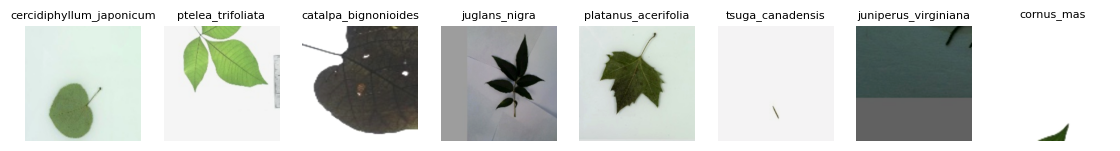

In [6]:
# 把被标准化过的张量还原成 0~1 的像素值，便于用 matplotlib 显示
def denormalize(t):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    return (t * std + mean).permute(1, 2, 0).clamp(0, 1)

# 展示前 4 张与最后 4 张训练样本及其类别名
idx_list = list(range(4)) + [len(train_ds) - 1 - i for i in range(4)]
fig, axes = plt.subplots(1, 8, figsize=(14, 3))
for ax, i in zip(axes, idx_list):
    img, y = train_ds[i]
    ax.imshow(denormalize(img))
    ax.set_title(idx2label[y], fontsize=8)
    ax.axis('off')
plt.show()

## 2. 定义模型（在 ImageNet 预训练的基础上微调）

使用在 ImageNet 上预训练好的 ResNet-18 作为源模型。
这里用 `weights=ResNet18_Weights.IMAGENET1K_V1` 指定预训练权重
（旧写法 `pretrained=True` 已弃用），权重会自动下载并缓存到本地。

In [7]:
# 查看源模型的输出层：fc 在 ImageNet 上输出 1000 类
pretrained_net = torchvision.models.resnet18(
    weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
pretrained_net.fc

Linear(in_features=512, out_features=1000, bias=True)

In [8]:
# 构建目标模型：复用源模型除 fc 外的全部结构与参数，
# 仅把最后一层全连接层替换成输出 176 类的线性层（512 -> 176），并做 Xavier 初始化。
finetune_net = torchvision.models.resnet18(
    weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
finetune_net.fc = nn.Linear(finetune_net.fc.in_features, num_classes)
nn.init.xavier_uniform_(finetune_net.fc.weight)

Parameter containing:
tensor([[ 0.0295, -0.0702,  0.0835,  ...,  0.0745,  0.0225,  0.0182],
        [-0.0716, -0.0446, -0.0551,  ..., -0.0560,  0.0135, -0.0590],
        [ 0.0433, -0.0218, -0.0653,  ...,  0.0135, -0.0367, -0.0467],
        ...,
        [ 0.0485, -0.0733,  0.0157,  ..., -0.0147,  0.0647,  0.0409],
        [-0.0182, -0.0311,  0.0769,  ...,  0.0733, -0.0756, -0.0903],
        [-0.0819, -0.0330, -0.0541,  ..., -0.0151,  0.0732,  0.0786]],
       requires_grad=True)

## 3. 微调训练

定义训练函数：

- 输出层 `fc` 的参数是随机初始化的，需要**较大的学习率**（设为 `10 * learning_rate`）从头训练；
- 其余层参数来自 ImageNet 预训练，已经足够好，用**较小的学习率** `learning_rate` 微调即可；
- 每个 epoch 在验证集上评估，并保存验证集准确率最高的模型，供之后预测使用。

In [9]:
def train_fine_tuning(net, train_iter, val_iter, learning_rate=3e-3,
                      num_epochs=10, weight_decay=3e-4, param_group=True):
    """微调训练函数。

    参数
    ----
    net           : 待训练的模型
    train_iter    : 训练集 DataLoader
    val_iter      : 验证集 DataLoader
    learning_rate : 基础学习率
    num_epochs    : 训练轮数
    weight_decay  : 权重衰减（L2 正则化）
    param_group   : 是否对输出层 fc 使用 10 倍学习率
    """
    # 优先使用 GPU
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    net = net.to(device)
    print('使用设备:', device)

    loss = nn.CrossEntropyLoss()

    if param_group:
        # 除 fc 外的所有参数用基础学习率
        params_1x = [p for name, p in net.named_parameters()
                     if name not in ('fc.weight', 'fc.bias')]
        trainer = torch.optim.SGD(
            [{'params': params_1x, 'lr': learning_rate},
             {'params': net.fc.parameters(), 'lr': learning_rate * 10}],
            lr=learning_rate, momentum=0.9, weight_decay=weight_decay)
    else:
        trainer = torch.optim.SGD(net.parameters(), lr=learning_rate,
                                  momentum=0.9, weight_decay=weight_decay)

    best_acc, best_state = 0.0, None
    for epoch in range(num_epochs):
        # ---------- 训练阶段 ----------
        net.train()
        train_loss, train_correct, train_total = 0.0, 0, 0
        for X, y in train_iter:
            X, y = X.to(device), y.to(device)
            trainer.zero_grad()          # 清空上一轮梯度
            y_hat = net(X)               # 前向传播
            l = loss(y_hat, y)           # 计算交叉熵损失
            l.backward()                 # 反向传播求梯度
            trainer.step()               # 按梯度更新参数
            train_loss += l.item() * y.numel()
            train_correct += (y_hat.argmax(dim=1) == y).sum().item()
            train_total += y.numel()

        # ---------- 验证阶段 ----------
        net.eval()
        val_correct, val_total = 0, 0
        with torch.no_grad():            # 验证时不需要梯度，省显存
            for X, y in val_iter:
                X, y = X.to(device), y.to(device)
                y_hat = net(X)
                val_correct += (y_hat.argmax(dim=1) == y).sum().item()
                val_total += y.numel()

        train_acc = train_correct / train_total
        val_acc   = val_correct   / val_total
        print(f'epoch {epoch + 1:2d}/{num_epochs}: '
              f'train loss {train_loss / train_total:.4f}, '
              f'train acc {train_acc:.4f}, val acc {val_acc:.4f}')

        # 保留验证集准确率最高的模型参数
        if val_acc > best_acc:
            best_acc = val_acc
            best_state = {k: v.cpu().clone() for k, v in net.state_dict().items()}

    print(f'最佳验证集准确率: {best_acc:.4f}')
    # 训练结束后恢复验证集上最优的权重，供预测使用
    net.load_state_dict(best_state)
    return net

In [ ]:
# 微调训练：基础学习率 1e-3（fc 层为 1e-2），共训练 10 个 epoch。
# 只想快速验证流程时，可临时把 num_epochs 改小（如 1）。
finetune_net = train_fine_tuning(finetune_net, train_iter, val_iter,
                                 learning_rate=3e-3, num_epochs=10)

使用设备: cuda
epoch  1/10: train loss 3.5366, train acc 0.2624, val acc 0.4658


## 4. 预测测试集并生成提交文件

用验证集上最优的模型对 `test.csv` 中的 8800 张图片逐批预测，
把预测出的类别索引映射回类别名，按 `sample_submission.csv` 的格式
（两列 `image,label`）保存为 `submission.csv`。

In [ ]:
# 读取测试集（无标签，只做与验证集相同的预处理）
test_ds  = LeafDataset(test_df, transform=test_augs, has_label=False)
test_iter = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                       num_workers=0)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
finetune_net = finetune_net.to(device)
finetune_net.eval()

preds = []   # 依次存放每张图的预测类别索引
with torch.no_grad():
    for X in test_iter:
        X = X.to(device)
        y_hat = finetune_net(X)
        preds.extend(y_hat.argmax(dim=1).cpu().tolist())

# 把类别索引映射回类别名
pred_labels = [idx2label[i] for i in preds]

# 组装成与 sample_submission.csv 相同的两列格式并保存
submission = pd.DataFrame({'image': test_df['image'], 'label': pred_labels})
submission.to_csv('submission.csv', index=False)
print(f'已生成 submission.csv，共 {len(submission)} 行预测结果')
submission.head()

In [ ]:
# 核对提交文件与 sample_submission.csv 的行数、列名、图片顺序是否一致
sample = pd.read_csv('sample_submission.csv')
print('列名一致   :', list(submission.columns) == list(sample.columns))
print('行数一致   :', len(submission) == len(sample))
print('图片顺序一致:', (submission['image'] == sample['image']).all())

## 小结

1. 本任务使用**迁移学习**：直接复用 ImageNet 上预训练的 ResNet-18 特征，只替换输出层。
2. 除输出层外的参数用较小的学习率**微调**，输出层用 10 倍学习率从头训练。
3. 划分出 20% 的**验证集**来监控训练并挑选最佳模型，防止过拟合。
4. 最终模型对 8800 张测试图片预测，生成符合格式要求的 `submission.csv`。

可进一步改进的方向：

- 换成更大的预训练模型（ResNet-50、EfficientNet 等）通常能进一步提升准确率；
- 使用余弦退火学习率调度、AdamW 优化器、更强的数据增广（旋转、CutMix 等）；
- 训练更多 epoch，或对验证集最优模型做测试时增广（TTA，把多次预测取平均）。